# Notebook 14 – EDA Mini Challenge

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("eda_challenge.csv")

display(df.head())

display(df.tail())

display(df.sample(5, random_state=42))

,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel
0,1001,2026-01-02,North,Electronics,Laptop,2,55000.0,0.10,99000.0,Online
1,1002,2026-01-03,South,Furniture,Chair,5,3000.0,0.05,14250.0,Store
2,1003,2026-01-04,East,Electronics,Phone,3,20000.0,0.10,54000.0,Online
3,1004,2026-01-05,West,Office Supplies,Notebook,20,100.0,0.00,2000.0,Store
4,1005,2026-01-06,NaN,Furniture,Desk,2,8000.0,0.05,15200.0,Online


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel
26,1027,2026-01-28,East,Furniture,Chair,4,3000.0,0.00,12000.0,Store
27,1028,2026-01-29,West,Office supply,Pen,60,20.0,0.10,1080.0,Store
28,1029,not_a_date,North,Electronics,Phone,2,20000.0,0.00,40000.0,Online
29,1030,2026-01-31,South,Furniture,Desk,3,8000.0,1.50,22800.0,Store
30,1024,2026-01-25,West,Electronics,Phone,2,20000.0,0.05,38000.0,Online


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel
27,1028,2026-01-29,West,Office supply,Pen,60,20.0,0.10,1080.0,Store
15,1016,2026-01-17,West,Office Supplies,NaN,25,100.0,0.00,2500.0,Online
23,1024,2026-01-25,West,Electronics,Phone,2,20000.0,0.05,38000.0,Online
17,1018,2026-01-19,South,Furniture,Desk,-2,8000.0,0.05,15200.0,Store
8,1009,2026-01-10,North,Furniture,Chair,4,NaN,0.00,12000.0,Store


### Understand the dataset


In [ ]:

Question: What does this dataset represent?

Answer:

This is a Retail Sales Dataset containing information about customer orders, products, quantities, prices, discounts, sales revenue, regions, and sales
channels.
    
Attribute	              Explanation
    
Domain	               Retail / E-commerce
Dataset type	       Structured data
Observation	           Individual order
Business bjective	   Analyze retail sales performance
Potential target	   Sales

Data format	CSV

Business questions we can investigate:
    
1. Which product category generates the highest revenue?
2. Which region contributes the most sales?
3. Does the online channel generate more revenue than physical stores?
4. How do discounts relate to sales?
5. Which products have unusual order quantities?

### Inspect dataset structure
Question: Identify rows, columns, dimensions, column names, data types, and memory usage.

In [5]:
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nIndex:")
print(df.index)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nMemory Usage:")
print(df.memory_usage(deep=True))

Dataset Shape: (31, 10)

Number of Rows: 31
Number of Columns: 10

Column Names:
['Order_ID', 'Order_Date', 'Region', 'Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Channel']

Index:
RangeIndex(start=0, stop=31, step=1)

Data Types:
Order_ID        int64
Order_Date        str
Region            str
Category          str
Product           str
Quantity        int64
Unit_Price    float64
Discount      float64
Sales         float64
Channel           str
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    31 non-null     int64  
 1   Order_Date  31 non-null     str    
 2   Region      30 non-null     str    
 3   Category    31 non-null     str    
 4   Product     30 non-null     str    
 5   Quantity    31 non-null     int64  
 6   Unit_Price  30 non-null     float64
 7   Discount    31 non-nu

#### Identify data types

Question: Classify columns into numerical, categorical, discrete, continuous, date/time, identifier, and target variables

In [ ]:
Column	    Classification

Order_ID	Identifier
Order_Date	Date/time
Region	    Categorical
Category	Categorical
Product	    Categorical
Quantity	Numerical, discrete
Unit_Price	Numerical, continuous
Discount	Numerical, continuous
Sales	    Numerical, continuous; target
Channel	    Categorical

Note: Quantity is discrete because it counts individual items. Unit price, discount, 
and sales are treated as continuous numerical variables for analysis.

In [6]:
df["Order_Date"] = pd.to_datetime(                   
    df["Order_Date"], 
    errors="coerce"
)

print(df.dtypes)

Order_ID               int64
Order_Date    datetime64[us]
Region                   str
Category                 str
Product                  str
Quantity               int64
Unit_Price           float64
Discount             float64
Sales                float64
Channel                  str
dtype: object


Observation:

- Order_ID should not be treated as a predictive numerical feature
- Order_Date needs date-time conversion
- Sales can be used as a target for a sales prediction problem
- Quantity, Unit_Price, Discount, Region, Category, and Channel may be potential predictors

#### Identify missing values

Question: Find total missing values, missing values by column, and percentages

In [7]:
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

display(missing_summary)

,Missing_Count,Missing_Percentage
Order_ID,0,0.000000
Order_Date,1,3.225806
Region,1,3.225806
Category,0,0.000000
Product,1,3.225806
Quantity,0,0.000000
Unit_Price,1,3.225806
Discount,0,0.000000
Sales,1,3.225806
Channel,0,0.000000


#### Identify duplicates

Question: Find completely duplicated rows and duplicate identifiers.

In [8]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Order IDs:",
      df["Order_ID"].duplicated().sum())

display(df[df.duplicated(keep=False)])

Duplicate Rows: 1
Duplicate Order IDs: 1


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel
23,1024,2026-01-25,West,Electronics,Phone,2,20000.0,0.05,38000.0,Online
30,1024,2026-01-25,West,Electronics,Phone,2,20000.0,0.05,38000.0,Online


#### Analyze numerical features

Question: Calculate central tendency and dispersion for numerical features.

In [10]:
numerical_columns = [
    "Quantity",
    "Unit_Price",
    "Discount",
    "Sales"
]

display(df[numerical_columns].describe())

,Quantity,Unit_Price,Discount,Sales
count,31.000000,30.000000,31.000000,30.000000
mean,12.709677,17416.000000,0.090323,31682.666667
std,22.381828,20516.208832,0.264707,32082.899294
min,-2.000000,20.000000,0.000000,800.000000
25%,2.000000,825.000000,0.000000,8000.000000
50%,3.000000,8000.000000,0.050000,15700.000000
75%,10.500000,20000.000000,0.100000,51562.500000
max,100.000000,55000.000000,1.500000,104500.000000


#### Analyze categorical features

Question: Identify unique categories, frequencies, category distribution, rare categories, and imbalance

In [11]:
categorical_columns = [
    "Region",
    "Category",
    "Product",
    "Channel"
]

for col in categorical_columns:

    print("\nColumn:", col)

    print("Unique Values:", df[col].nunique())

    print("\nFrequency:")
    print(df[col].value_counts(dropna=False))

    print("\nPercentage:")
    print(
        df[col].value_counts(
            normalize=True,
            dropna=False
        ) * 100
    )


Column: Region
Unique Values: 4

Frequency:
Region
South    8
West     8
North    7
East     7
NaN      1
Name: count, dtype: int64

Percentage:
Region
South    25.806452
West     25.806452
North    22.580645
East     22.580645
NaN       3.225806
Name: proportion, dtype: float64

Column: Category
Unique Values: 4

Frequency:
Category
Electronics        13
Furniture          10
Office Supplies     7
Office supply       1
Name: count, dtype: int64

Percentage:
Category
Electronics        41.935484
Furniture          32.258065
Office Supplies    22.580645
Office supply       3.225806
Name: proportion, dtype: float64

Column: Product
Unique Values: 6

Frequency:
Product
Phone       7
Laptop      6
Chair       5
Desk        5
Pen         4
Notebook    3
NaN         1
Name: count, dtype: int64

Percentage:
Product
Phone       22.580645
Laptop      19.354839
Chair       16.129032
Desk        16.129032
Pen         12.903226
Notebook     9.677419
NaN          3.225806
Name: proportion, dtype: 

#### Detect outliers

Question: Apply the IQR method to numerical features.

In [13]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print("\nFeature:", col)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Outlier Count:", len(outliers))

    display(outliers)


Feature: Quantity
Lower Bound: -10.75
Upper Bound: 23.25
Outlier Count: 6


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel
6,1007,2026-01-08,East,Office Supplies,Pen,50,20.0,0.00,1000.0,Store
9,1010,2026-01-11,South,Office Supplies,Notebook,30,100.0,0.10,2700.0,Online
12,1013,2026-01-14,North,Office Supplies,Pen,100,20.0,0.05,1900.0,Store
15,1016,2026-01-17,West,Office Supplies,NaN,25,100.0,0.00,2500.0,Online
18,1019,2026-01-20,East,Office Supplies,Pen,40,20.0,0.00,800.0,Store
27,1028,2026-01-29,West,Office supply,Pen,60,20.0,0.10,1080.0,Store



Feature: Unit_Price
Lower Bound: -27937.5
Upper Bound: 48762.5
Outlier Count: 6


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel
0,1001,2026-01-02,North,Electronics,Laptop,2,55000.0,0.10,99000.0,Online
5,1006,2026-01-07,South,Electronics,Laptop,1,55000.0,0.00,55000.0,Online
10,1011,2026-01-12,East,Electronics,Laptop,2,55000.0,0.05,104500.0,Online
16,1017,2026-01-18,North,Electronics,Laptop,1,55000.0,0.10,49500.0,Online
20,1021,2026-01-22,North,Electronics,Laptop,2,55000.0,0.05,104500.0,Online
25,1026,2026-01-27,South,Electronics,Laptop,1,55000.0,0.05,52250.0,Online



Feature: Discount
Lower Bound: -0.15000000000000002
Upper Bound: 0.25
Outlier Count: 1


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel
29,1030,2026-01-31,South,Furniture,Desk,3,8000.0,1.5,22800.0,Store



Feature: Sales
Lower Bound: -57343.75
Upper Bound: 116906.25
Outlier Count: 0


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Discount,Sales,Channel


#### Analyze data distributions

Question: Identify distribution shape, center, spread, skewness, and kurtosis.


Feature: Quantity
Mean: 12.709677419354838
Median: 3.0
Skewness: 2.615629207014743
Kurtosis: 7.379768958374324


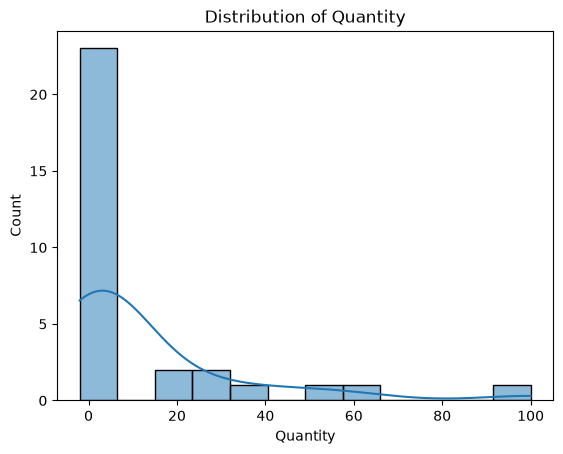


Feature: Unit_Price
Mean: 17416.0
Median: 8000.0
Skewness: 1.1152489696939702
Kurtosis: -0.24623462475105695


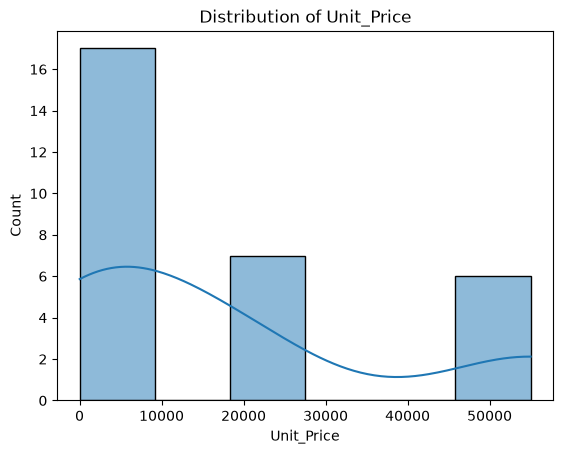


Feature: Discount
Mean: 0.09032258064516129
Median: 0.05
Skewness: 5.3632817406645
Kurtosis: 29.434673710645313


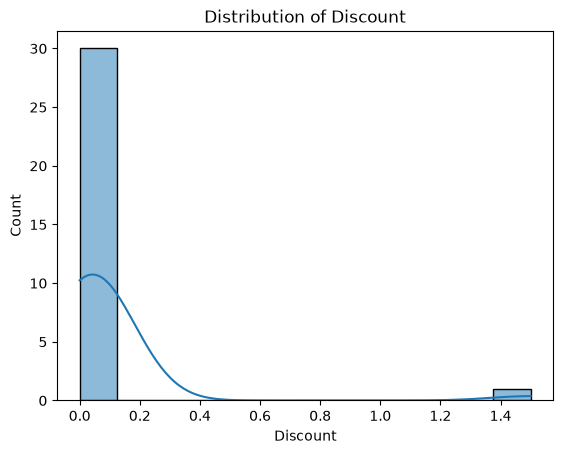


Feature: Sales
Mean: 31682.666666666668
Median: 15700.0
Skewness: 1.0944980986428847
Kurtosis: 0.28635184554207616


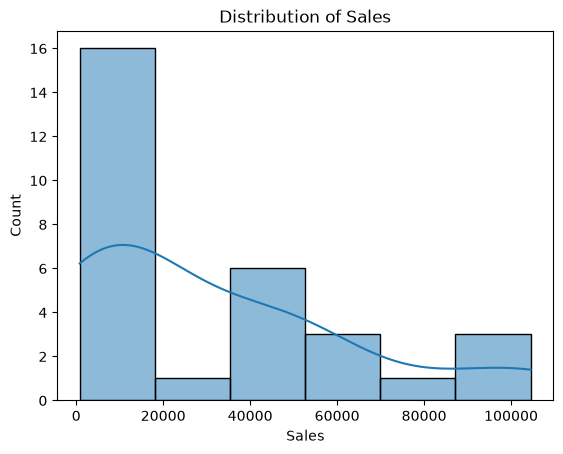

In [16]:
for col in numerical_columns:

    print("\nFeature:", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())

    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())

    sns.histplot(df[col], kde=True)

    plt.title(f"Distribution of {col}")
    plt.show()

#### Analyze correlations

Question: Identify strong positive, strong negative, weak, and potentially correlated numerical features.

In [17]:
correlation_matrix = df[
    numerical_columns
].corr()

display(correlation_matrix)

,Quantity,Unit_Price,Discount,Sales
Quantity,1.000000,-0.431514,-0.081508,-0.443398
Unit_Price,-0.431514,1.000000,-0.055996,0.865634
Discount,-0.081508,-0.055996,1.000000,-0.019854
Sales,-0.443398,0.865634,-0.019854,1.000000


Question: Create visualizations that help identify important business patterns

#### Sales by product category


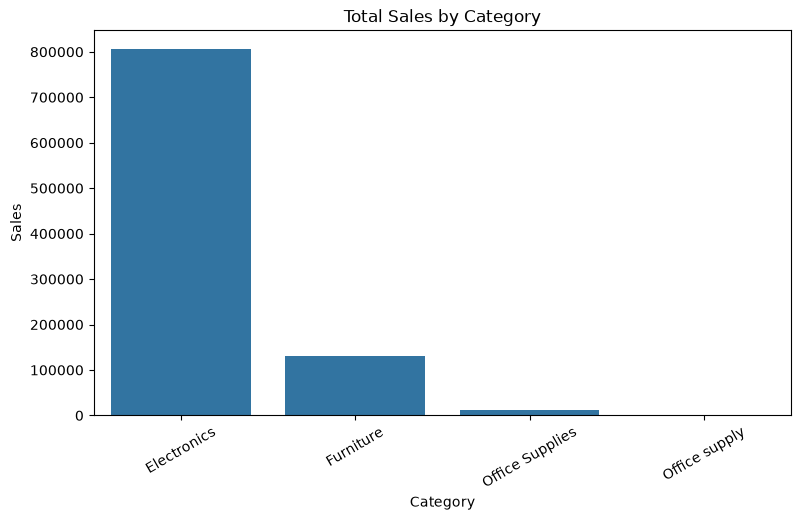

In [18]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Category",
    y="Sales",
    estimator="sum",
    errorbar=None
)

plt.title("Total Sales by Category")
plt.xticks(rotation=30)
plt.show()

#### Sales by region

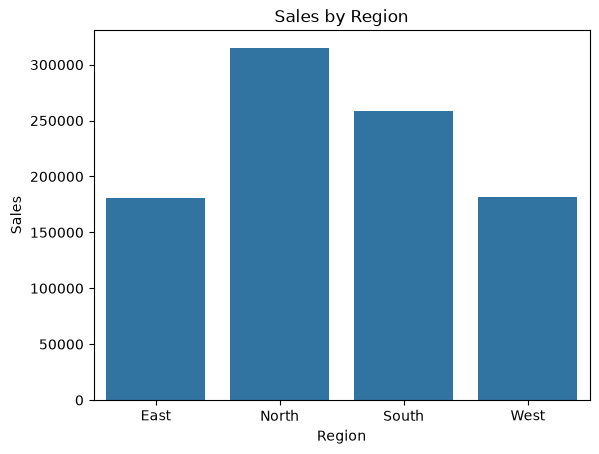

In [19]:
region_sales = df.groupby(
    "Region",
    dropna=False
)["Sales"].sum().reset_index()

sns.barplot(
    data=region_sales,
    x="Region",
    y="Sales"
)

plt.title("Sales by Region")
plt.show()

#### Sales by channel

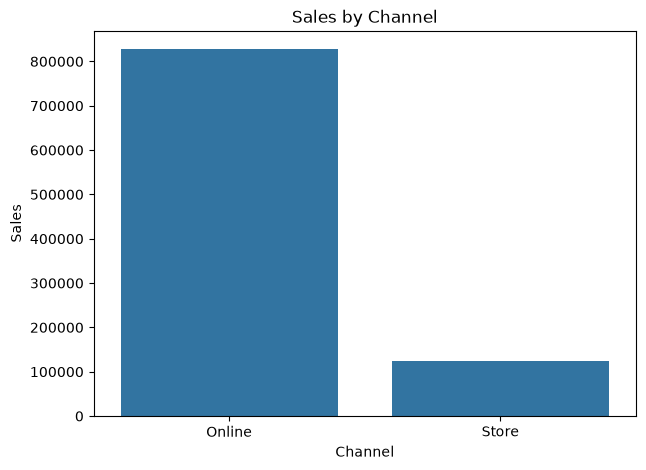

In [20]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Channel",
    y="Sales",
    estimator="sum",
    errorbar=None
)

plt.title("Sales by Channel")
plt.show()

#### Quantity vs Sales

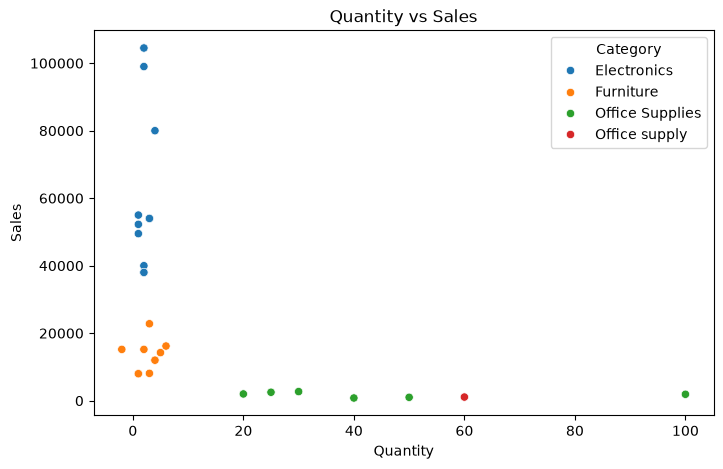

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Quantity",
    y="Sales",
    hue="Category"
)

plt.title("Quantity vs Sales")
plt.show()

#### Unit Price vs Sales

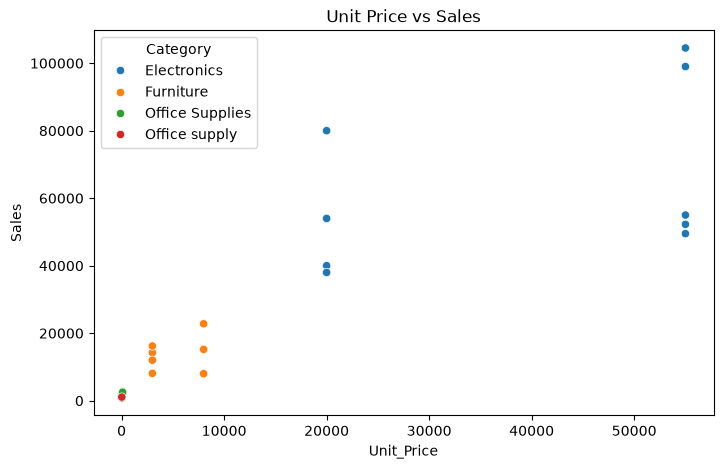

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Unit_Price",
    y="Sales",
    hue="Category"
)

plt.title("Unit Price vs Sales")
plt.show()

#### Multiple feature relationships

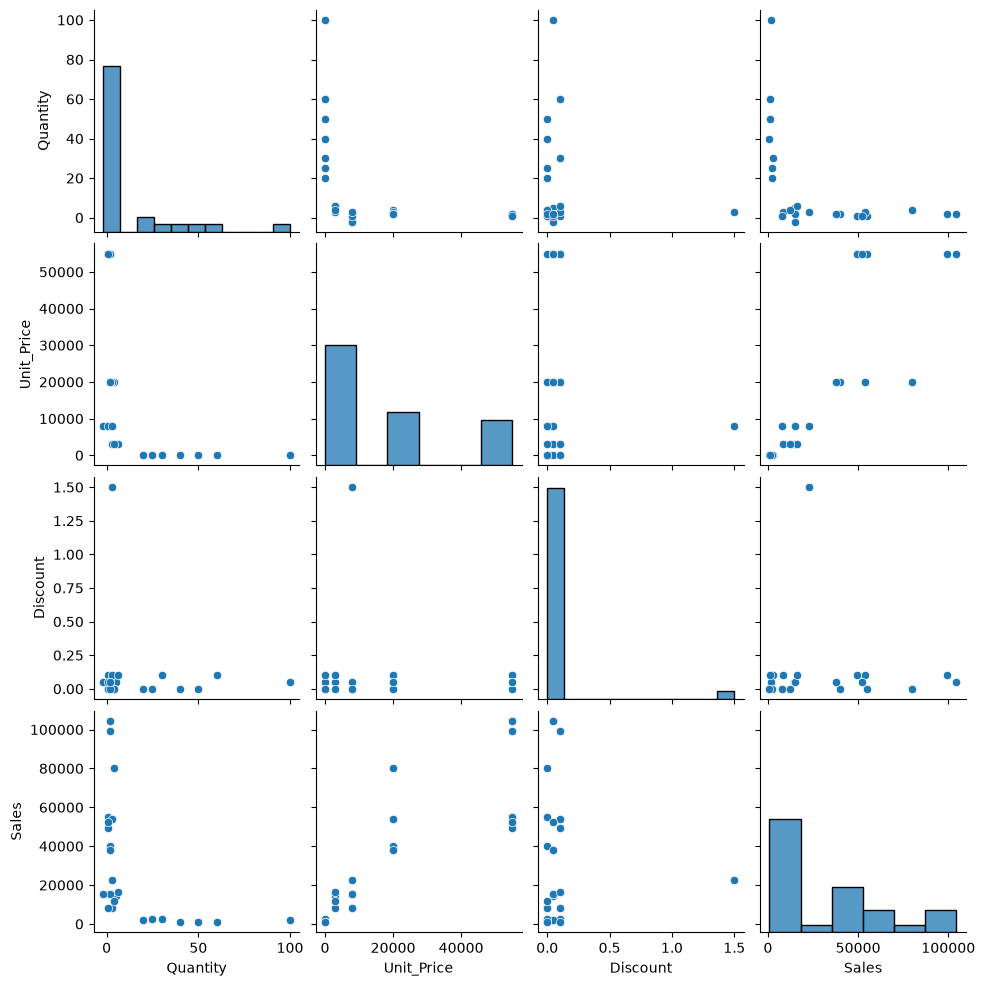

In [23]:
sns.pairplot(
    df[numerical_columns].dropna()
)

plt.show()

#### Question: Identify at least five important patterns from the dataset.

In [ ]:
No.  	Pattern	            Observation

1	Category performance	Electronics contributes the highest sales
2	Channel performance	    Online generates more revenue than Store
3	Product pricing    	    Laptop has a higher price than other products
4	Quantity	            Low-priced products are often ordered in larger quantities
5	Distribution	        Sales distribution is right-skewed
6	Missing data	        Four missing values are present
7	Duplicates	            One duplicate record exists

In [24]:
category_sales = (                       #investigate category sales:
    df.groupby("Category", dropna=False)["Sales"]
      .sum()
      .sort_values(ascending=False)
)

display(category_sales)

Category
Electronics        806750.0
Furniture          131750.0
Office Supplies     10900.0
Office supply        1080.0
Name: Sales, dtype: float64

#### Question: Convert your EDA observations into meaningful business insights

Business Insight 1: Electronics performance
Electronics contributes approximately 84.2% of recorded sales.

Interpretation: Electronics is the major revenue-generating category.

Recommendation: Maintain sufficient inventory of high-demand electronic products and investigate opportunities to increase sales of other categories.
Business Insight 2: Online sales performance
Online sales contribute approximately 86.5% of recorded revenue.

Interpretation: The online channel is the largest revenue contributor in this sample.

Recommendation: Investigate online customer behavior and maintain a reliable online purchasing experience.
Business Insight 3: Product pricing
High-priced products such as laptops generate substantial revenue even when order quantities are relatively low.

Interpretation: Revenue depends on both product price and quantity.

Recommendation: Analyze product-level profit margins before deciding which products to promote.
Business Insight 4: Quantity and revenue
Some products have high quantities but relatively low sales because their unit prices are low.

Interpretation: High sales volume does not necessarily mean high revenue.

Recommendation: Evaluate products using both quantity sold and revenue generated.
Business Insight 5: Data quality
The dataset contains missing values, duplicate records, invalid discounts, negative quantities, and inconsistent category names.

Interpretation: The dataset is not ready for reliable predictive modeling or final business reporting.

Recommendation: Complete data cleaning and validation before building reports or machine learning models.

#### Based on your EDA findings, what preprocessing activities should be performed?

In [ ]:
Issue	                           Recommendedaction	                                     Reason

Missing Region	                   Recover or impute	                             Complete regional analysis
Missing Product	                   Investigate source	                             Identify the correct product
Missing Unit_Price	             Recover from product records	                      Maintain pricing accuracy
Missing Sales	                 Validate and recalculate if appropriate	         Ensure reliable target values
Duplicate records	             Remove verified duplicates	                         Avoid double counting
Negative Quantity	             Investigate and correct	                         Quantity cannot normally be negative
Discount 1.50	                   Validate and correct                             	Discount proportion is invalid
Category spelling	             Standardize categories	                             Avoid duplicate category groups
Invalid date	                 Recover or mark missing	                         Enable time-based analysis
Identifier	                    Exclude Order_ID from model features	          Avoid treating IDs as meaningful predictors
Numerical features	                  Consider scaling	                          Support suitable ML algorithms
Categorical features	              Apply encoding	                          Convert categories into model-compatible values

In [25]:

clean_df = df.copy()

clean_df["Category"] = (
    clean_df["Category"]
    .replace({
        "Office supply": "Office Supplies"
    })
)

clean_df["Order_Date"] = pd.to_datetime(
    clean_df["Order_Date"],
    errors="coerce"
)

clean_df.loc[
    clean_df["Quantity"] < 0,
    "Quantity"
] = np.nan

clean_df.loc[
    (clean_df["Discount"] < 0) |
    (clean_df["Discount"] > 1),
    "Discount"
] = np.nan

display(clean_df.isnull().sum())

Order_ID      0
Order_Date    1
Region        1
Category      0
Product       1
Quantity      1
Unit_Price    1
Discount      1
Sales         1
Channel       0
dtype: int64